## ML1 – Method decision (before fitting)

**Main model:** Truncated SVD. **Comparison (ML5):** PCA (arpack), same k, same matrix.

**Why SVD**
1. **Sparse data:** A is 5,473 × 3,687, 413,927 non-zeros (97.95% sparse, 4.99 MB).
   SVD uses it as is. PCA centres columns, turning every zero into a negative
   value, so the maths runs on a dense matrix (161 MB if built).
2. **Fits the job:** one fit gives product factors (Vᵀ) for "also bought"
   similarity and customer factors (U·S) for scoring.
3. **Meaning:** uncentred, component 1 = overall volume/popularity. This keeps the
   popularity signal, which matters in Q4. Risk: suggestions drift towards best sellers.

**Prediction:** SVD beats PCA on hit@10, fit time and peak memory; PCA gives the
cleaner customer map.

**k rule (R2):** k is chosen from the reconstruction-error curve plus storage/speed,
before any test hit rate is computed. Test hit@10 is then reported for all
k ∈ {10, 20, 50, 100, 200} as sensitivity only.

**Would change my mind if:** PCA beats SVD on hit@10 by > 3% points at similar
cost, or SVD fails to beat the best-seller baseline.

In [148]:
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.sparse as sp
import time
from sklearn.decomposition import TruncatedSVD

# load the A matrix, customer index, product index and test pair matrix from the processed files

SEED = 42

# Find the project root (same function as the DE notebook)
def project_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / ".git").exists():
            return p
    raise FileNotFoundError("No .git folder found above " + str(start))

ROOT = project_root()
PROCESSED = ROOT / "data" / "processed"
REPORTS = ROOT / "reports"
print("Project root:", ROOT)

#  Load the training matrix
A = sp.load_npz(PROCESSED / "A_train.npz")
print("Type:", type(A))
print("Shape:", A.shape, "| non-zeros:", A.nnz)

customer_list = pd.read_parquet(PROCESSED / "customer_index.parquet")["Customer ID"].tolist()
product_list = pd.read_parquet(PROCESSED / "product_index.parquet")["StockCode"].tolist()
test_pairs_matrix = pd.read_parquet(PROCESSED / "test_pairs_matrix.parquet")
print("Customers:", len(customer_list), "| Products:", len(product_list))
print("Test pairs:", len(test_pairs_matrix),
      "| Eval customers:", test_pairs_matrix["Customer ID"].nunique())


Project root: /Users/muhammadsaadmalik/MS AI/Fall2026/Linear Algebra/Mini Projects/customers-like-you
Type: <class 'scipy.sparse._csr.csr_matrix'>
Shape: (5473, 3687) | non-zeros: 413927
Customers: 5473 | Products: 3687
Test pairs: 44727 | Eval customers: 1913


In [149]:
############## ML1. ###################
squared_forbenius_norm = round((A.data ** 2).sum(), 2)
print("Squared Frobenius Norm:", squared_forbenius_norm)

Squared Frobenius Norm: 2390381.95


In [150]:
def fit_svd(A, k, squared_forbenius_norm, seed=42):
    """Fit Truncated SVD with k components and return the key numbers."""
    start_perf = time.perf_counter()

    svd_model = TruncatedSVD(n_components=k, random_state=seed)
    svd_model.fit(A)

    end_perf = time.perf_counter()
    execution_time = end_perf - start_perf

    energy_kept = (svd_model.singular_values_ ** 2).sum()
    rel_error = np.sqrt(max(0.0, 1 - energy_kept / squared_forbenius_norm))
    factors_mb = (A.shape[0] + A.shape[1]) * k * 8 / 1000000

    return {"k": k, "execution_time (s)": execution_time, "relative_error": rel_error,
            "factors_mb": factors_mb, "svd_model": svd_model}

In [151]:
k_list = [10, 20, 50, 100, 200]
warm_up = fit_svd(A, 1, squared_forbenius_norm, seed=SEED)

models = {}
rows = []

for k in k_list:
    result = fit_svd(A, k, squared_forbenius_norm, seed=SEED)
    models[k] = result.pop("svd_model")                         # model kept separately, will use later on
    rows.append(result)
curve = pd.DataFrame(rows)
print(curve)

     k  execution_time (s)  relative_error  factors_mb
0   10            0.033090        0.875917      0.7328
1   20            0.045993        0.845705      1.4656
2   50            0.075334        0.789583      3.6640
3  100            0.132647        0.727785      7.3280
4  200            0.268556        0.639466     14.6560


In [152]:
curve["gain_per_component"] = -curve["relative_error"].diff() / curve["k"].diff()

sparse_mb = (A.data.nbytes + A.indices.nbytes + A.indptr.nbytes) / 1e6
breakeven_k = sparse_mb * 1e6 / ((A.shape[0] + A.shape[1]) * 8)

print(f"Break-even point: {breakeven_k:.2f} components")
curve.to_csv(REPORTS / "ml2_svd_curve.csv", index=False)

Break-even point: 68.08 components


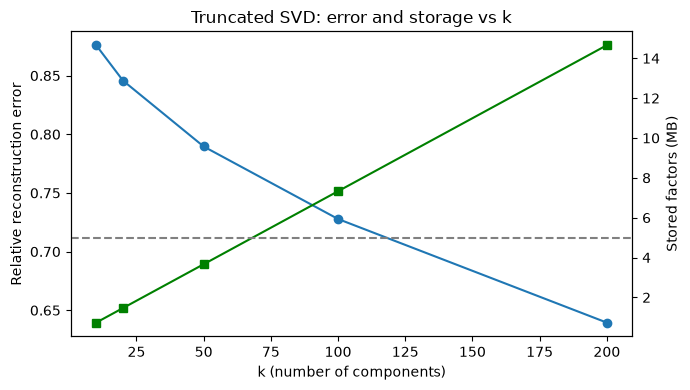

In [153]:
import matplotlib.pyplot as plt

FIGURES = REPORTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(curve["k"], curve["relative_error"], marker="o", label="Relative error")
ax1.set_xlabel("k (number of components)")
ax1.set_ylabel("Relative reconstruction error")

ax2 = ax1.twinx()                                   # second y-axis, same x
ax2.plot(curve["k"], curve["factors_mb"], marker="s", color="green", label="Factor size (MB)")
ax2.axhline(4.99, linestyle="--", color="grey")     # sparse matrix size
ax2.set_ylabel("Stored factors (MB)")

ax1.set_title("Truncated SVD: error and storage vs k")
fig.tight_layout()
fig.savefig(FIGURES / "ml2_error_vs_k.png", dpi=150)   # saving kept outside functions
plt.show()

**Chosen k = 50.** No sharp elbow (error gain per 10 components: 3.0 → 1.9 → 1.2 → 0.9 points), so storage decides:
factors exceed the 4.99 MB sparse matrix above k ≈ 68. k = 50 (3.66 MB) is the largest tested k below that.
Chosen before any test hit rate (R2).

In [154]:
############## ML3. ###################
from sklearn.preprocessing import normalize

print(models[50].components_.shape)
# print(models[50].components_)
#transpose
model50_transposed = models[50].components_.transpose()
print(model50_transposed.shape)
#normalise
P = normalize(model50_transposed, axis=1) #normalised_model50_transposed
#print(P)
row_lengths = np.linalg.norm(P, axis=1)
print("Row lengths min/max:", row_lengths.min(), row_lengths.max())
# assert P.shape == (len(product_list), 50)
# assert np.allclose(row_lengths, 1.0)


(50, 3687)
(3687, 50)
Row lengths min/max: 0.9999999999999994 1.0000000000000007


In [155]:
def similar_products(product_index, P, n=10):
    """Return the n products most similar to product (cosine similarity)."""
    scores = P @ P[product_index]                 # Step 1: similarity of every product to j
    scores[product_index] = -np.inf               # Step 2: never recommend itself
    top = np.argsort(-scores)[:n]                 # Step 3: get the indices of the top n scores
    return top

In [156]:
similar_products_dict = {}
for i in range(len(product_list)):
    similar = similar_products(i, P, n=10)
    similar_products_dict[product_list[i]] = [product_list[j] for j in similar]

similar_products_df = pd.DataFrame(similar_products_dict, index=range(1, 11))
similar_products_df.index.name = "rank"

print(similar_products_df.shape)                # (10, 3687)
print(similar_products_df.iloc[:, :3])          # first 3 products only, top 10 recommendations
assert similar_products_df.shape == (10, len(product_list))

similar_products_df.to_csv(REPORTS / "also_bought_k50.csv")
print("File size MB:", round((REPORTS / "also_bought_k50.csv").stat().st_size / 1e6, 2))

(10, 3687)
       10002   10080   10120
rank                        
1      21789   22609   90087
2      21708   20716  90120D
3      21731  16169E  37489D
4      21441   16236  37489B
5      21915  16161G   90086
6      21788   79320  37489C
7     84796B   23321  37489A
8     62096B   21374   84548
9      21316   22610  16020C
10     23084   21213  35838A
File size MB: 0.25


In [157]:
def score_customer(i, A, P):
    """Score all products for the customer in row i of A (bought items masked)."""
    a = A[i]                                          # Step 1: what they bought
    customer_vec = a @ P                              # Step 2: customer arrow (50 numbers)
    scores = customer_vec @ P.T                       # Step 3: score every product
    scores = np.asarray(scores).ravel()               # Step 4: make it a flat list
    scores[a.indices] = -np.inf                       # Step 5: hide what they already bought
    return scores

def recommend(i, A, P, n=10):
    """Return the indices of the n best new products for customer row i."""
    scores = score_customer(i, A, P)
    top = np.argsort(-scores)[:n]                     # highest scores first
    return top

In [158]:
# checking on a random customer
i = 6
train = pd.read_parquet(PROCESSED / "train.parquet")
descriptions = train.groupby("StockCode")["Description"].first()
recs = recommend(i, A, P)

print(f"Customer #{i} bought {A[i].nnz} products, for example:")
for j in A[i].indices[:5]:
    print("   ", descriptions[product_list[j]])

print(f"Top 10 recommendations for customer #{i}:")
for j in recs:
    print("   ", descriptions[product_list[j]])

# Checks
assert len(recs) == 10                                # exactly 10
assert not set(recs) & set(A[i].indices)              # nothing already bought

Customer #6 bought 57 products, for example:
    SET/10 RED SPOTTY PARTY CANDLES
    SET/10 PINK SPOTTY PARTY CANDLES
    COOK WITH WINE METAL SIGN 
    GIN + TONIC DIET METAL SIGN
    PLEASE ONE PERSON  METAL SIGN
Top 10 recommendations for customer #6:
    RECIPE BOX PANTRY YELLOW DESIGN
    CERAMIC BOWL WITH STRAWBERRY DESIGN
    JAM MAKING SET WITH JARS
    LADIES & GENTLEMEN METAL SIGN
    PANTRY ROLLING PIN
    SET 2 PANTRY DESIGN TEA TOWELS
    CERAMIC PLATE STRAWBERRY DESIGN
    JAM MAKING SET PRINTED
    CERAMIC CHERRY CAKE MONEY BANK
    TOAST ITS - HAPPY BIRTHDAY


In [159]:
##### verification of shapes and sizes
a = A[0]
print("A:", A.shape)                       # (5473, 3687)
print("a = A[0]:", a.shape)                # (1, 3687)
print("P:", P.shape)                       # (3687, 50)
customer_vec = a @ P
print("a @ P:", customer_vec.shape)        # (1, 50)
scores = customer_vec @ P.T
print("(a @ P) @ P.T:", scores.shape)      # (1, 3687)

A: (5473, 3687)
a = A[0]: (1, 3687)
P: (3687, 50)
a @ P: (1, 50)
(a @ P) @ P.T: (1, 3687)


In [160]:
########################### ML4 ##############################
K_CHOSEN = 50

# ===== Chunk 1: answer key =====
def build_answer_key(test_pairs_matrix, customer_list, product_list):
    """For each test customer, find which products they bought in the test period.

    Returns a dictionary: customer row number -> set of product column numbers.
    """
    # Step 1: lookup tables from ID to position in the matrix
    customer_to_row = {}
    for row_number, customer_id in enumerate(customer_list):
        customer_to_row[customer_id] = row_number

    product_to_col = {}
    for col_number, stock_code in enumerate(product_list):
        product_to_col[stock_code] = col_number

    # Step 2: go through the test pairs one by one and file them per customer
    answer_key = {}
    for customer_id, stock_code in zip(test_pairs_matrix["Customer ID"],
                                       test_pairs_matrix["StockCode"]):
        row = customer_to_row[customer_id]      # KeyError here = pair not in matrix
        col = product_to_col[stock_code]

        if row not in answer_key:               # first time we see this customer
            answer_key[row] = set()
        answer_key[row].add(col)

    return answer_key


answer_key = build_answer_key(test_pairs_matrix, customer_list, product_list)

# Step 3: count what we got
n_customers = len(answer_key)
n_pairs = 0
for products in answer_key.values():
    n_pairs = n_pairs + len(products)

print("Evaluation customers:", n_customers)
print("Held-out pairs:", n_pairs)

# Step 4: checks against the DE numbers
assert n_customers == 1913
assert n_pairs == len(test_pairs_matrix)       # 44,727

Evaluation customers: 1913
Held-out pairs: 44727


In [161]:
# ===== hit rate =====
def hit_rate(answer_key, top_n):
    """Share of evaluation customers with at least one held-out product in their top-n."""
    hits = 0
    for row, held_out_products in answer_key.items():
        recommended_products = set(top_n[row])               # this customer's top-n
        common = recommended_products & held_out_products    # products in both sets
        if len(common) > 0:
            hits = hits + 1
    return hits / len(answer_key)

In [162]:
# =====  model recommendations for all customers =====
def product_vectors(model):
    """One row per product, each row scaled to length 1."""
    vectors = model.components_.T
    vectors = normalize(vectors, axis=1)
    return vectors

def score_all_customers(A, P, n=10, batch_size=500):
    """Top-n new products for every customer, 500 customers at a time."""
    n_customers = A.shape[0]
    top_n = np.zeros((n_customers, n), dtype=int)

    for start in range(0, n_customers, batch_size):
        stop = min(start + batch_size, n_customers)

        # Step 1: take a block of customers
        A_batch = A[start:stop]

        # Step 2: score every product for every customer in the block
        customer_vectors = A_batch @ P             # (batch, k)
        scores = customer_vectors @ P.T            # (batch, products)

        # Step 3: hide products each customer already bought
        bought = A_batch.nonzero()                 # (row numbers, column numbers)
        bought_rows = bought[0]
        bought_cols = bought[1]
        scores[bought_rows, bought_cols] = -np.inf

        # Step 4: keep the n highest scores in each row
        order = np.argsort(-scores, axis=1)
        top_n[start:stop] = order[:, :n]

    return top_n

P = product_vectors(models[K_CHOSEN])

start_time = time.perf_counter()
model_top10 = score_all_customers(A, P, n=10)
score_seconds = time.perf_counter() - start_time
print("Scored all customers in", round(score_seconds, 2), "seconds")
print("Recommendation table shape:", model_top10.shape)

# Check: batch version gives the same answer as the ML3 function
for row in [0, 100, 2000]:
    one_by_one = recommend(row, A, P, n=10)
    assert (model_top10[row] == one_by_one).all(), f"mismatch for customer #{row}"
print("Batch scoring matches recommend()")

model_hit_rate = hit_rate(answer_key, model_top10)
print("Model hit@10:", round(model_hit_rate, 4))

Scored all customers in 0.76 seconds
Recommendation table shape: (5473, 10)
Batch scoring matches recommend()
Model hit@10: 0.2148


In [163]:
# =====  best-seller baseline =====
def best_seller_top_n(A, n=10):
    """For every customer: the n most popular products they have not bought yet."""
    # Step 1: how many customers bought each product (training data only)
    customers_per_product = A.getnnz(axis=0)

    # Step 2: product numbers from most to least popular
    popularity_order = np.argsort(-customers_per_product)

    # Step 3: walk down the list for each customer, skipping what they own
    n_customers = A.shape[0]
    top_n = np.zeros((n_customers, n), dtype=int)
    for row in range(n_customers):
        already_bought = set(A[row].indices)
        picks = []
        for product in popularity_order:
            if product not in already_bought:
                picks.append(product)
            if len(picks) == n:
                break
        top_n[row] = picks

    return top_n, popularity_order

baseline_top10, popularity_order = best_seller_top_n(A, n=10)
baseline_hit_rate = hit_rate(answer_key, baseline_top10)
print("Baseline hit@10:", round(baseline_hit_rate, 4))

for row in [0, 100, 2000]:
    overlap = set(baseline_top10[row]) & set(A[row].indices)
    assert len(overlap) == 0, f"baseline recommends a bought product to customer #{row}"

Baseline hit@10: 0.2687


In [164]:
# ===== results table =====
gap_points = (model_hit_rate - baseline_hit_rate) * 100

results = pd.DataFrame({
    "method": [f"Truncated SVD (k={K_CHOSEN})", "Best-seller baseline"],
    "hit_rate_at_10_%": [round(model_hit_rate * 100, 1), round(baseline_hit_rate * 100, 1)],
})
print(results.to_string(index=False))

if gap_points > 3:
    verdict = "model clearly beats the baseline"
elif gap_points < -3:
    verdict = "model clearly LOSES to the baseline"
else:
    verdict = "within noise (±3 points), no clear winner"
print(f"Gap: {gap_points:+.1f} points -> {verdict}")

results.to_csv(REPORTS / "ml4_results.csv", index=False)

              method  hit_rate_at_10_%
Truncated SVD (k=50)              21.5
Best-seller baseline              26.9
Gap: -5.4 points -> model clearly LOSES to the baseline


In [165]:
# ===== nightly job timing =====
def build_also_bought(P, n=10):
    """Top-n most similar products for every product."""
    similarity = P @ P.T                       # products x products
    np.fill_diagonal(similarity, -np.inf)      # a product is not its own suggestion
    order = np.argsort(-similarity, axis=1)
    return order[:, :n]

# Part 1: fit
start_time = time.perf_counter()
job_model = TruncatedSVD(n_components=K_CHOSEN, random_state=SEED).fit(A)
fit_seconds = time.perf_counter() - start_time

# Part 2: product pages table
start_time = time.perf_counter()
job_P = product_vectors(job_model)
job_also_bought = build_also_bought(job_P, n=10)
also_bought_seconds = time.perf_counter() - start_time

# Part 3: recommendations for every customer
start_time = time.perf_counter()
job_top10 = score_all_customers(A, job_P, n=10)
customer_seconds = time.perf_counter() - start_time

total_seconds = fit_seconds + also_bought_seconds + customer_seconds

timing = pd.DataFrame({
    "step": ["fit SVD", "also-bought table", "score all customers", "total"],
    "seconds": [round(fit_seconds, 3), round(also_bought_seconds, 3),
                round(customer_seconds, 3), round(total_seconds, 3)],
})
print(timing.to_string(index=False))
timing.to_csv(REPORTS / "ml4_nightly_timing.csv", index=False)

               step  seconds
            fit SVD    0.076
  also-bought table    0.530
score all customers    0.743
              total    1.349


In [166]:
# ===== hit rate for every k (report only) =====
sensitivity_rows = []
for k in models:
    P_k = product_vectors(models[k])
    top10_k = score_all_customers(A, P_k, n=10)
    hit_rate_k = hit_rate(answer_key, top10_k)
    sensitivity_rows.append({
        "k": k,
        "model_hit_rate_%": round(hit_rate_k * 100, 1),
        "baseline_hit_rate_%": round(baseline_hit_rate * 100, 1),
        "gap_points": round((hit_rate_k - baseline_hit_rate) * 100, 1),
    })
    print(f"k={k}: hit@10 = {hit_rate_k:.4f}")

sensitivity = pd.DataFrame(sensitivity_rows)
print(sensitivity.to_string(index=False))
sensitivity.to_csv(REPORTS / "ml4_sensitivity_k.csv", index=False)

k=10: hit@10 = 0.1479
k=20: hit@10 = 0.1830
k=50: hit@10 = 0.2148
k=100: hit@10 = 0.2269
k=200: hit@10 = 0.2159
  k  model_hit_rate_%  baseline_hit_rate_%  gap_points
 10              14.8                 26.9       -12.1
 20              18.3                 26.9        -8.6
 50              21.5                 26.9        -5.4
100              22.7                 26.9        -4.2
200              21.6                 26.9        -5.3


In [170]:
import tracemalloc
from sklearn.decomposition import PCA

########################### ML5 ##############################

# ===== Chunk 1: fit both methods, measuring time and peak memory =====
def fit_and_measure(model, A):
    """Fit a model on A. Return the fitted model, seconds taken and peak memory in MB."""
    tracemalloc.start()
    start_time = time.perf_counter()

    model.fit(A)

    fit_seconds = time.perf_counter() - start_time
    current_bytes, peak_bytes = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    peak_mb = peak_bytes / 1e6
    return model, fit_seconds, peak_mb

svd_model, svd_seconds, svd_peak_mb = fit_and_measure(
    TruncatedSVD(n_components=K_CHOSEN, random_state=SEED), A)
print(f"SVD: {svd_seconds:.3f} s, peak memory {svd_peak_mb:.1f} MB")

pca_model, pca_seconds, pca_peak_mb = fit_and_measure(
    PCA(n_components=K_CHOSEN, svd_solver="arpack", random_state=SEED), A)
print(f"PCA: {pca_seconds:.3f} s, peak memory {pca_peak_mb:.1f} MB")


# ===== Chunk 2: information kept, in each method's own language =====
# Step 1: total "energy" of A (sum of squares of all cells, zeros add nothing)
norm_A_squared = (A.data ** 2).sum()

# Step 2: SVD rebuild error (from zero)
svd_kept = (svd_model.singular_values_ ** 2).sum()
svd_rel_error = np.sqrt(1 - svd_kept / norm_A_squared)

# Step 3: PCA explained variance (around the average customer)
pca_explained = pca_model.explained_variance_ratio_.sum()

# Step 4: PCA rebuild error on the same scale as SVD, so the two can be compared
# PCA rebuild = average customer + k components, so the error is what is left
# after removing the average AND the k components
n_customers = A.shape[0]
column_means = pca_model.mean_
energy_of_average = n_customers * (column_means ** 2).sum()
pca_kept = (pca_model.singular_values_ ** 2).sum()
pca_rel_error = np.sqrt((norm_A_squared - energy_of_average - pca_kept) / norm_A_squared)

print(f"SVD relative rebuild error: {svd_rel_error:.4f}")
print(f"PCA explained variance:     {pca_explained:.4f}")
print(f"PCA relative rebuild error: {pca_rel_error:.4f}")

# Check the PCA error formula on a small dense slice (rebuild for real, compare)
small = A[:200].toarray()
small_pca = PCA(n_components=K_CHOSEN, random_state=SEED).fit(small)
rebuilt = small_pca.inverse_transform(small_pca.transform(small))
direct = np.linalg.norm(small - rebuilt) / np.linalg.norm(small)
formula = np.sqrt(((small ** 2).sum() - 200 * (small_pca.mean_ ** 2).sum()
                   - (small_pca.singular_values_ ** 2).sum()) / (small ** 2).sum())
print(f"Check on 200 customers: direct {direct:.4f} vs formula {formula:.4f}")
assert abs(direct - formula) < 1e-6


# ===== Chunk 3: size of stored factors =====
n_products = A.shape[1]
svd_factors_mb = (n_customers + n_products) * K_CHOSEN * 8 / 1e6
pca_factors_mb = ((n_customers + n_products) * K_CHOSEN + n_products) * 8 / 1e6   # + column means
print(f"Stored factors: SVD {svd_factors_mb:.2f} MB, PCA {pca_factors_mb:.2f} MB")


# ===== Chunk 4: hit rate with each method's product vectors =====
svd_P = product_vectors(svd_model)
pca_P = product_vectors(pca_model)

svd_top10 = score_all_customers(A, svd_P, n=10)
pca_top10 = score_all_customers(A, pca_P, n=10)

svd_hit_rate = hit_rate(answer_key, svd_top10)
pca_hit_rate = hit_rate(answer_key, pca_top10)
print(f"Hit@10: SVD {svd_hit_rate:.4f}, PCA {pca_hit_rate:.4f}, baseline {baseline_hit_rate:.4f}")


# ===== Chunk 5: what component 1 means =====
def describe_component(model, product_list, descriptions, component=0, n=8):
    """Print sign balance and the top products at both ends of one component."""
    loadings = model.components_[component]

    n_positive = (loadings > 0).sum()
    share_same_sign = max(n_positive, len(loadings) - n_positive) / len(loadings)
    print(f"  {share_same_sign:.0%} of products have the same sign")

    order = np.argsort(loadings)
    print("  Highest loadings:")
    for j in order[::-1][:n]:
        print(f"    {loadings[j]:+.3f}  {descriptions[product_list[j]]}")
    print("  Lowest loadings:")
    for j in order[:n]:
        print(f"    {loadings[j]:+.3f}  {descriptions[product_list[j]]}")
    return share_same_sign

print("SVD component 1:")
svd_same_sign = describe_component(svd_model, product_list, descriptions)
print("PCA component 1:")
pca_same_sign = describe_component(pca_model, product_list, descriptions)

# Does SVD component 1 track volume? Compare customer scores with total purchases
svd_scores_c1 = svd_model.transform(A)[:, 0]
customer_totals = np.asarray(A.sum(axis=1)).ravel()
corr = np.corrcoef(np.abs(svd_scores_c1), customer_totals)[0, 1]
print(f"Correlation of |SVD comp 1 score| with customer total: {corr:.3f}")


# ===== Chunk 6: comparison table =====
comparison = pd.DataFrame({
    "Measure": [
        "k used",
        "Fit time (seconds)",
        "Peak memory during fit (MB)",
        "Size of stored factors (MB)",
        "Variance explained (PCA) / relative rebuild error (SVD)",
        "Relative rebuild error (same scale for both)",
        "Hit rate at 10 on held-out purchases (%)",
        "Best-seller baseline hit rate at 10 (%)",
        "What component 1 represents",
    ],
    "PCA": [
        K_CHOSEN, round(pca_seconds, 3), round(pca_peak_mb, 1), round(pca_factors_mb, 2),
        f"{pca_explained:.1%} variance explained", round(pca_rel_error, 4),
        round(pca_hit_rate * 100, 1), round(baseline_hit_rate * 100, 1),
        "Customer size: how much more than the average customer someone buys of the core best-selling range (cake cases, jumbo bags, lunch bags, T-light holders). Almost all loadings share one sign.",
    ],
    "Truncated SVD": [
        K_CHOSEN, round(svd_seconds, 3), round(svd_peak_mb, 1), round(svd_factors_mb, 2),
        f"{svd_rel_error:.1%} rebuild error", round(svd_rel_error, 4),
        round(svd_hit_rate * 100, 1), round(baseline_hit_rate * 100, 1),
        "Overall purchase volume: how much a customer buys, led by the same core best-sellers. All loadings share one sign; customer scores correlate 0.968 with total purchases.",
    ],
})
print(comparison.to_string(index=False))
comparison.to_csv(REPORTS / "ml5_pca_vs_svd.csv", index=False)

pca_scores_c1 = pca_model.transform(A)[:, 0]
corr_pca = np.corrcoef(np.abs(pca_scores_c1), customer_totals)[0, 1]
print(f"Correlation of |PCA comp 1 score| with customer total: {corr_pca:.3f}")

SVD: 0.123 s, peak memory 9.7 MB
PCA: 0.105 s, peak memory 7.8 MB
SVD relative rebuild error: 0.7896
PCA explained variance:     0.3499
PCA relative rebuild error: 0.7887
Check on 200 customers: direct 0.4852 vs formula 0.4852
Stored factors: SVD 3.66 MB, PCA 3.69 MB
Hit@10: SVD 0.2148, PCA 0.2101, baseline 0.2687
SVD component 1:
  100% of products have the same sign
  Highest loadings:
    +0.130  PACK OF 72 RETRO SPOT CAKE CASES
    +0.122  WHITE HANGING HEART T-LIGHT HOLDER
    +0.108  JUMBO BAG RED WHITE SPOTTY 
    +0.101  LUNCH BAG RED SPOTTY
    +0.092  60 TEATIME FAIRY CAKE CASES
    +0.088  ASSORTED COLOUR BIRD ORNAMENT
    +0.085  PACK OF 60 PINK PAISLEY CAKE CASES
    +0.081  LUNCHBAG SPACEBOY DESIGN 
  Lowest loadings:
    +0.000  AMBER GLASS TASSLE BAG CHARM
    +0.000  SILVER LARIAT 40CM
    +0.000  PINK SQUARE COMPACT MIRROR
    +0.000  PURPLE GLASS TASSLE BAG CHARM
    +0.000  S/6 PAPER BOXES BLOSSOM IMAGES 
    +0.000  FOUR PICTURE WHITE GLASS FRAME
    +0.000  MARAKE

In [168]:
print("PCA component 2:")
describe_component(pca_model, product_list, descriptions, component=1)
print("PCA component 3:")
describe_component(pca_model, product_list, descriptions, component=2)

PCA component 2:
  72% of products have the same sign
  Highest loadings:
    +0.210  WHITE HANGING HEART T-LIGHT HOLDER
    +0.124  HEART OF WICKER SMALL
    +0.105  HEART OF WICKER LARGE
    +0.103  PLEASE ONE PERSON  METAL SIGN
    +0.103  ASSORTED COLOUR BIRD ORNAMENT
    +0.103  WOODEN PICTURE FRAME WHITE FINISH
    +0.101  WOODEN FRAME ANTIQUE WHITE 
    +0.100  RED HANGING HEART T-LIGHT HOLDER
  Lowest loadings:
    -0.091  PACK OF 72 RETRO SPOT CAKE CASES
    -0.091  PLASTERS IN TIN SPACEBOY
    -0.089  MINI PAINT SET VINTAGE 
    -0.089  ROUND SNACK BOXES ,SET4, WOODLAND 
    -0.087  SPACEBOY LUNCH BOX 
    -0.086  LUNCHBAG SPACEBOY DESIGN 
    -0.085  RED TOADSTOOL LED NIGHT LIGHT
    -0.084  PLASTERS IN TIN WOODLAND ANIMALS
PCA component 3:
  64% of products have the same sign
  Highest loadings:
    +0.235  JUMBO BAG RED WHITE SPOTTY 
    +0.183  JUMBO BAG PINK WITH WHITE SPOTS
    +0.166  JUMBO STORAGE BAG SUKI
    +0.162  JUMBO BAG STRAWBERRY
    +0.161  LUNCH BAG RED SPO

np.float64(0.6417141307295905)

Taste coordinates shape: (5473, 2)
Customers with no taste signal (length 0): 0
3 groups: silhouette 0.548
4 groups: silhouette 0.534
5 groups: silhouette 0.530
6 groups: silhouette 0.523
Chosen number of groups: 3

Group 0: 1901 customers (35%), median 21 products each
  Top countries: United Kingdom 90%, Germany 2%, France 2%
  Most bought:
    27% of group  JUMBO BAG RED WHITE SPOTTY 
    23% of group  LUNCH BAG RED SPOTTY
    21% of group  LUNCHBAG SPACEBOY DESIGN 
    20% of group  LUNCH BAG CARS BLUE
    20% of group  LUNCHBAG SUKI  DESIGN 
  Most distinctive (lift):
    x1.9  CHARLOTTE BAG APPLES DESIGN
    x1.9  JUMBO BAG DOLLY GIRL DESIGN
    x1.9  JUMBO BAG SPACEBOY DESIGN
    x1.9  JUMBO STORAGE BAG SUKI
    x1.9  JUMBO BAG APPLES

Group 1: 1940 customers (35%), median 57 products each
  Top countries: United Kingdom 97%, Spain 0%, Cyprus 0%
  Most bought:
    52% of group  WHITE HANGING HEART T-LIGHT HOLDER
    30% of group  HEART OF WICKER SMALL
    30% of group  REGENCY C

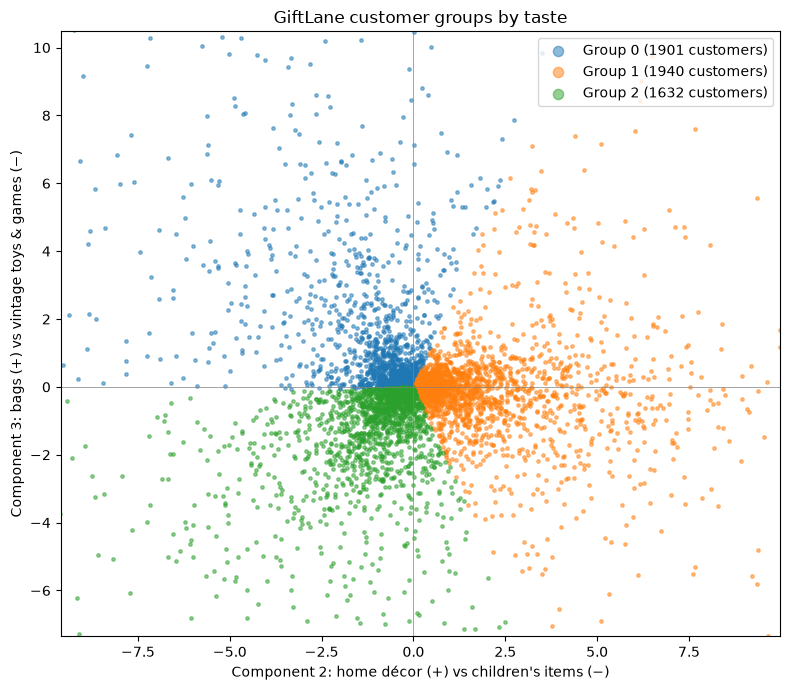

segment  customers  share_%  median_products
Group 0       1901     34.7             21.0
Group 1       1940     35.4             57.0
Group 2       1632     29.8             47.0


In [171]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import normalize
import matplotlib.pyplot as plt

########################### ML6 ##############################

# ===== Chunk 1: taste coordinates per customer =====
# Step 1: PCA scores for every customer (centred, one column per component)
customer_scores = pca_model.transform(A)                 # (customers, k)

# Step 2: keep components 2 and 3 (taste axes). Component 1 = customer size (ML5),
#         so mapping it would group customers by how much they buy, not what they buy
taste = customer_scores[:, 1:3]                          # (customers, 2)

# Step 3: scale each customer to length 1, so only their MIX of tastes is left
#         (a big buyer and a small buyer with the same taste get the same point)
taste_direction = normalize(taste, axis=1)
print("Taste coordinates shape:", taste_direction.shape)
assert taste_direction.shape == (A.shape[0], 2)

lengths = np.linalg.norm(taste_direction, axis=1)
print("Customers with no taste signal (length 0):", (lengths == 0).sum())


# ===== Chunk 2: choose the number of groups (3 to 6) =====
silhouette_rows = []
for n_groups in range(3, 7):
    kmeans = KMeans(n_clusters=n_groups, n_init=10, random_state=SEED)
    labels = kmeans.fit_predict(taste_direction)
    score = silhouette_score(taste_direction, labels, random_state=SEED)
    silhouette_rows.append({"n_groups": n_groups, "silhouette": round(score, 3)})
    print(f"{n_groups} groups: silhouette {score:.3f}")
silhouette_table = pd.DataFrame(silhouette_rows)

best_row = silhouette_table["silhouette"].idxmax()
N_GROUPS = int(silhouette_table.loc[best_row, "n_groups"])
print("Chosen number of groups:", N_GROUPS)

kmeans = KMeans(n_clusters=N_GROUPS, n_init=10, random_state=SEED)
labels = kmeans.fit_predict(taste_direction)


# ===== Chunk 3: describe each group =====
# Step 1: one country per customer, in the same order as the matrix rows
country_by_customer = train.groupby("Customer ID")["Country"].agg(lambda s: s.mode().iloc[0])
customer_country = country_by_customer.reindex(customer_list).to_numpy()
assert len(customer_country) == A.shape[0]

# Step 2: 1 = bought, 0 = not (amounts ignored), and the share of ALL customers per product
bought = A.copy()
bought.data[:] = 1
share_all = np.asarray(bought.mean(axis=0)).ravel()

# Step 3: products per customer, to compare group sizes fairly
products_per_customer = np.asarray(bought.sum(axis=1)).ravel()

def describe_group(group, labels, bought, share_all, customer_country, n=5, min_share=0.05):
    """Print and return size, countries, most bought and most distinctive products of one group."""
    in_group = labels == group
    n_members = in_group.sum()

    # countries
    country_counts = pd.Series(customer_country[in_group]).value_counts(normalize=True)
    top_countries = []
    for country, share in country_counts.head(3).items():
        top_countries.append(f"{country} {share:.0%}")

    # share of group members who bought each product
    share_group = np.asarray(bought[in_group].mean(axis=0)).ravel()

    # distinctive = bought much more often in this group than overall (lift)
    lift = np.zeros_like(share_group)
    common_enough = (share_group >= min_share) & (share_all > 0)
    lift[common_enough] = share_group[common_enough] / share_all[common_enough]

    most_bought = []
    for j in np.argsort(-share_group)[:n]:
        most_bought.append(descriptions[product_list[j]].strip())

    distinctive_idx = []
    for j in np.argsort(-lift)[:n]:
        if lift[j] > 0:                          # only products that passed the filter
            distinctive_idx.append(j)
    distinctive = []
    for j in distinctive_idx:
        distinctive.append(descriptions[product_list[j]].strip())

    median_products = np.median(products_per_customer[in_group])

    print(f"\nGroup {group}: {n_members} customers ({n_members / len(labels):.0%}), "
          f"median {median_products:.0f} products each")
    print("  Top countries:", ", ".join(top_countries))
    print("  Most bought:")
    for j in np.argsort(-share_group)[:n]:
        print(f"    {share_group[j]:.0%} of group  {descriptions[product_list[j]]}")
    print("  Most distinctive (lift):")
    if len(distinctive_idx) == 0:
        print(f"    none: no product bought by >= {min_share:.0%} of this group")
    for j in distinctive_idx:
        print(f"    x{lift[j]:.1f}  {descriptions[product_list[j]]}")

    return {
        "group": group,
        "customers": int(n_members),
        "share_%": round(100 * n_members / len(labels), 1),
        "median_products": median_products,
        "top_countries": "; ".join(top_countries),
        "distinctive_products": "; ".join(distinctive),
        "most_bought_products": "; ".join(most_bought),
    }

group_rows = []
for group in range(N_GROUPS):
    group_rows.append(describe_group(group, labels, bought, share_all, customer_country))
segment_summary = pd.DataFrame(group_rows)


# ===== Chunk 4: name the groups (fill these in after reading Chunk 3) =====
segment_names = {}
for group in range(N_GROUPS):
    segment_names[group] = f"Group {group}"        # e.g. "Home décor shops"
segment_summary["segment"] = segment_summary["group"].map(segment_names)


# ===== Chunk 5: the map =====
# Plot the taste scores (before scaling), coloured by group.
# Groups are decided by direction, so they appear as wedges from the centre.
fig, ax = plt.subplots(figsize=(8, 7))
for group in range(N_GROUPS):
    in_group = labels == group
    ax.scatter(taste[in_group, 0], taste[in_group, 1], s=6, alpha=0.5,
               label=f"{segment_names[group]} ({in_group.sum()} customers)")

# zoom to where most customers are (a few huge buyers would squash the plot)
x_low, x_high = np.percentile(taste[:, 0], [1, 99])
y_low, y_high = np.percentile(taste[:, 1], [1, 99])
ax.set_xlim(x_low, x_high)
ax.set_ylim(y_low, y_high)
ax.axhline(0, color="grey", linewidth=0.5)
ax.axvline(0, color="grey", linewidth=0.5)

ax.set_xlabel("Component 2: home décor (+) vs children's items (−)")
ax.set_ylabel("Component 3: bags (+) vs vintage toys & games (−)")
ax.set_title("GiftLane customer groups by taste")
ax.legend(markerscale=3, loc="best")
fig.tight_layout()
fig.savefig(REPORTS / "figures" / "ml6_customer_map.png", dpi=150)
plt.show()


# ===== Chunk 6: save the segment table (no customer IDs, R4) =====
segment_summary = segment_summary[["segment", "customers", "share_%", "median_products",
                                   "top_countries", "distinctive_products", "most_bought_products"]]
print(segment_summary[["segment", "customers", "share_%", "median_products"]].to_string(index=False))
segment_summary.to_csv(REPORTS / "ml6_segments.csv", index=False)